# 06season: the 2026 haze season and the typhoons

Part B of PF5 (the indirect effect). Uses the files prepared by `05season`; no downloads.

| Section | Question |
|---|---|
| 2 | How did fires, smoke and the cities' air develop from August to October, and when were typhoons active? |
| 3 | **Indirect effect**: on days with a typhoon in the Philippine Sea, is the smoke over Sumatra, Kalimantan, Kuala Lumpur and Singapore higher or lower than usual? And do rain, wind, the boundary layer and the fires themselves change? |
| 4 | Maps: how a typhoon day differs from other days across the region |
| 5 | Season animation (daily smoke, fires and storms) |

**How "typhoon day" is defined.** A day is a typhoon day when at least one western Pacific system with maximum winds of at least 64 knots (typhoon strength, IBTrACS/JTWC values) has a track point inside the Philippine Sea box (120E to 150E, 5N to 25N) that day. Both numbers are settings; Section 3 also prints the result for a looser definition (tropical storms of at least 34 knots in a larger box) as a check.

**How "higher or lower than usual" is measured.** Smoke built up through the season, so comparing typhoon days with all other days would mostly compare early and late season. Instead each daily value is compared with its own 15-day running mean (the "anomaly"), and the typhoon-day anomalies are compared with the other days' anomalies. Uncertainty comes from a block bootstrap (resampling 5-day blocks, because one hazy day is usually followed by another). With one season of 86 days the result is a first indication, not proof; the climatology in Part C (2003 to 2025) is the real test.

## Section 0: settings

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
SEASON_DIR = PROJECT_DIR / "data" / "processed" / "season"
RAW_SEASON = PROJECT_DIR / "data" / "raw" / "season"
COAST_DIR = PROJECT_DIR / "data" / "raw" / "naturalearth"
FIG_DIR = SEASON_DIR / "figures"
FRAME_DIR = SEASON_DIR / "frames"

# Regions as (west, east, south, north), same as Part A
REGIONS = {}
REGIONS["Sumatra"] = (95.0, 106.0, -6.0, 4.0)  # <-
REGIONS["Kalimantan"] = (108.0, 118.5, -4.5, 2.0)  # <-
REGIONS["Eastern Indonesia"] = (119.0, 141.0, -9.0, 2.0)  # <-
REGIONS["Pacific corridor"] = (128.0, 150.0, 3.0, 18.0)  # <-
CITIES = {"Kuala Lumpur": (3.14, 101.69), "Singapore": (1.35, 103.82)}  # <- (lat, lon)

TC_MIN_KT = 64  # <- typhoon strength (knots)
TC_BOX = (120.0, 150.0, 5.0, 25.0)  # <- Philippine Sea (west, east, south, north)
TC_MIN_KT_LOOSE = 34  # <- check: tropical storm strength
TC_BOX_LOOSE = (115.0, 160.0, 5.0, 30.0)  # <- check: larger box

ANOMALY_WINDOW_DAYS = 15  # <- running mean used as "usual" for each day
BOOT_BLOCK_DAYS = 5  # <- block length for the bootstrap
BOOT_REPS = 2000  # <- bootstrap repetitions
FIRMS_FILE = "firms_cells_VIIRS_NOAA20_NRT.csv"  # <- NOAA-20 is complete for all days
WHO_24H = 15.0  # <-

MAP_EXTENT = (90.0, 160.0, -15.0, 30.0)  # <-
SMOKE_LEVELS = [0, 1, 2, 5, 10, 15, 25, 35, 55.5, 100, 250, 500]  # <- VISUAL
REGION_COLORS = {"Sumatra": "#2a78d6", "Kalimantan": "#eb6834", "Eastern Indonesia": "#1baf7a", "Pacific corridor": "#eda100"}  # <- VISUAL
CITY_COLORS = {"Kuala Lumpur": "#6250d6", "Singapore": "#e87ba4"}  # <- VISUAL
TC_SHADE = "#e4e2dc"  # <- VISUAL: shading of typhoon days
GIF_FPS = 4  # <- VISUAL

## Section 1: imports and data

In [2]:
import json
import warnings
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.path import Path as MplPath
from PIL import Image

warnings.filterwarnings("ignore", message="Ambiguous reference date string")
for d in [FIG_DIR, FRAME_DIR]:
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.facecolor"] = "#fcfcfb"
plt.rcParams["axes.facecolor"] = "#fcfcfb"
plt.rcParams["axes.edgecolor"] = "#a8a7a2"
plt.rcParams["font.size"] = 10
rng = np.random.default_rng(7)

geos = xr.open_dataset(SEASON_DIR / "geosfp_daily.nc")[["pm25", "smoke", "sssmass25", "totexttau"]].load()
era5 = xr.open_dataset(SEASON_DIR / "era5_daily.nc").load()
era5["wspd"] = np.hypot(era5["u10"], era5["v10"])
DAYS = pd.to_datetime(geos.time.values)
print("GEOS-FP daily:", len(DAYS), "days,", DAYS[0].date(), "to", DAYS[-1].date(), " grid", geos.sizes["lat"], "x", geos.sizes["lon"])
print("ERA5 daily:", era5.sizes["time"], "days")

tracks = pd.read_csv(SEASON_DIR / "season_tracks.csv", parse_dates=["time"])
tracks["wind"] = pd.to_numeric(tracks["USA_WIND"], errors="coerce")
tracks["day"] = tracks["time"].dt.normalize()


def tc_days(min_kt, box):
    s = tracks[(tracks["wind"] >= min_kt) & tracks["LON"].between(box[0], box[1]) & tracks["LAT"].between(box[2], box[3])]
    return pd.Series(DAYS.isin(s["day"].unique()), index=DAYS)


TC = tc_days(TC_MIN_KT, TC_BOX)
TC_LOOSE = tc_days(TC_MIN_KT_LOOSE, TC_BOX_LOOSE)
names_by_day = tracks[(tracks["wind"] >= TC_MIN_KT) & tracks["LON"].between(TC_BOX[0], TC_BOX[1]) & tracks["LAT"].between(TC_BOX[2], TC_BOX[3])].groupby("day")["NAME"].agg(lambda s: ", ".join(sorted(set(s))))
print(f"Typhoon days (at least {TC_MIN_KT} kt in the Philippine Sea box): {int(TC.sum())} of {len(DAYS)}")
print(f"Loose check (at least {TC_MIN_KT_LOOSE} kt in the larger box): {int(TC_LOOSE.sum())} of {len(DAYS)}")
print("Storms counted:", ", ".join(sorted(set(", ".join(names_by_day.values).split(", ")))))

GEOS-FP daily: 86 days, 2026-08-01 to 2026-10-25  grid 121 x 113
ERA5 daily: 86 days
Typhoon days (at least 64 kt in the Philippine Sea box): 22 of 86
Loose check (at least 34 kt in the larger box): 63 of 86
Storms counted: CHAMPI, CHOI-WAN, DOLPHIN, KOGUMA, SAUDEL, SURIGAE


In [3]:
# Fire hotspots per region and day (NOAA-20 VIIRS, cells on Indonesian land)
countries = json.loads((COAST_DIR / "ne_50m_admin_0_countries.geojson").read_text(encoding="utf8"))["features"]
indo = [f for f in countries if f["properties"]["NAME"] == "Indonesia"][0]["geometry"]
INDO_PATHS = [MplPath(np.array(p[0])) for p in (indo["coordinates"] if indo["type"] == "MultiPolygon" else [indo["coordinates"]])]


def in_indonesia(lat, lon, half=0.25):
    # A 0.5 degree cell counts if its centre or any corner is on Indonesian land
    hit = np.zeros(len(lat), dtype=bool)
    for dy, dx in [(0, 0), (half, half), (half, -half), (-half, half), (-half, -half)]:
        pts = np.column_stack([np.asarray(lon) + dx, np.asarray(lat) + dy])
        for path in INDO_PATHS:
            hit |= path.contains_points(pts)
    return hit


fc = pd.read_csv(RAW_SEASON / FIRMS_FILE, parse_dates=["date"])
cell_keys = fc[["cell_lat", "cell_lon"]].drop_duplicates()
cell_keys["indo"] = in_indonesia(cell_keys["cell_lat"].values, cell_keys["cell_lon"].values)
fc = fc.merge(cell_keys, on=["cell_lat", "cell_lon"])
fc = fc[fc["indo"]]
fire_daily = {}
for name, b in REGIONS.items():
    if name == "Pacific corridor":
        continue
    sub = fc[fc["cell_lon"].between(b[0], b[1]) & fc["cell_lat"].between(b[2], b[3])]
    fire_daily[name] = sub.groupby("date")["hotspots"].sum().reindex(DAYS, fill_value=0)
fire_daily = pd.DataFrame(fire_daily)
print("VIIRS NOAA-20 hotspots on Indonesian land, season total by region:")
print(fire_daily.sum().astype(int).to_string())

VIIRS NOAA-20 hotspots on Indonesian land, season total by region:
Sumatra               69571
Kalimantan           286092
Eastern Indonesia    143148


In [4]:
# Daily series: smoke and weather over each region, smoke at each city
def region_mean(da, box):
    sub = da.sel(lon=slice(box[0], box[1]), lat=slice(box[2], box[3]))
    return sub.weighted(np.cos(np.deg2rad(sub.lat))).mean(["lat", "lon"]).to_series()


series = {}
for name, b in REGIONS.items():
    series[(name, "smoke")] = region_mean(geos["smoke"], b)
    series[(name, "rain")] = region_mean(era5["tp"], b)
    series[(name, "blh")] = region_mean(era5["blh"], b)
    series[(name, "wspd")] = region_mean(era5["wspd"], b)
    series[(name, "v10")] = region_mean(era5["v10"], b)
    if name in fire_daily:
        series[(name, "hotspots")] = fire_daily[name]
for city, (clat, clon) in CITIES.items():
    series[(city, "smoke")] = geos["smoke"].interp(lat=clat, lon=clon).to_series()
    series[(city, "pm25")] = geos["pm25"].interp(lat=clat, lon=clon).to_series()
    series[(city, "rain")] = era5["tp"].interp(lat=clat, lon=clon).to_series()
    series[(city, "blh")] = era5["blh"].interp(lat=clat, lon=clon).to_series()
daily = pd.DataFrame(series)
daily.index = DAYS
daily.columns = pd.MultiIndex.from_tuples(daily.columns, names=["place", "variable"])
daily[("All", "typhoon_day")] = TC.values
daily.to_csv(SEASON_DIR / "season_daily_series.csv")
print("Season means of smoke PM2.5 (micrograms per m3):")
print(daily.xs("smoke", axis=1, level="variable").mean().round(1).to_string())

Season means of smoke PM2.5 (micrograms per m3):
place
Sumatra              25.5
Kalimantan           37.4
Eastern Indonesia    12.0
Pacific corridor      5.9
Kuala Lumpur         47.1
Singapore            57.2


## Section 2: the season at a glance

Shaded days: a typhoon of at least 64 knots in the Philippine Sea box. Each panel has its own scale.

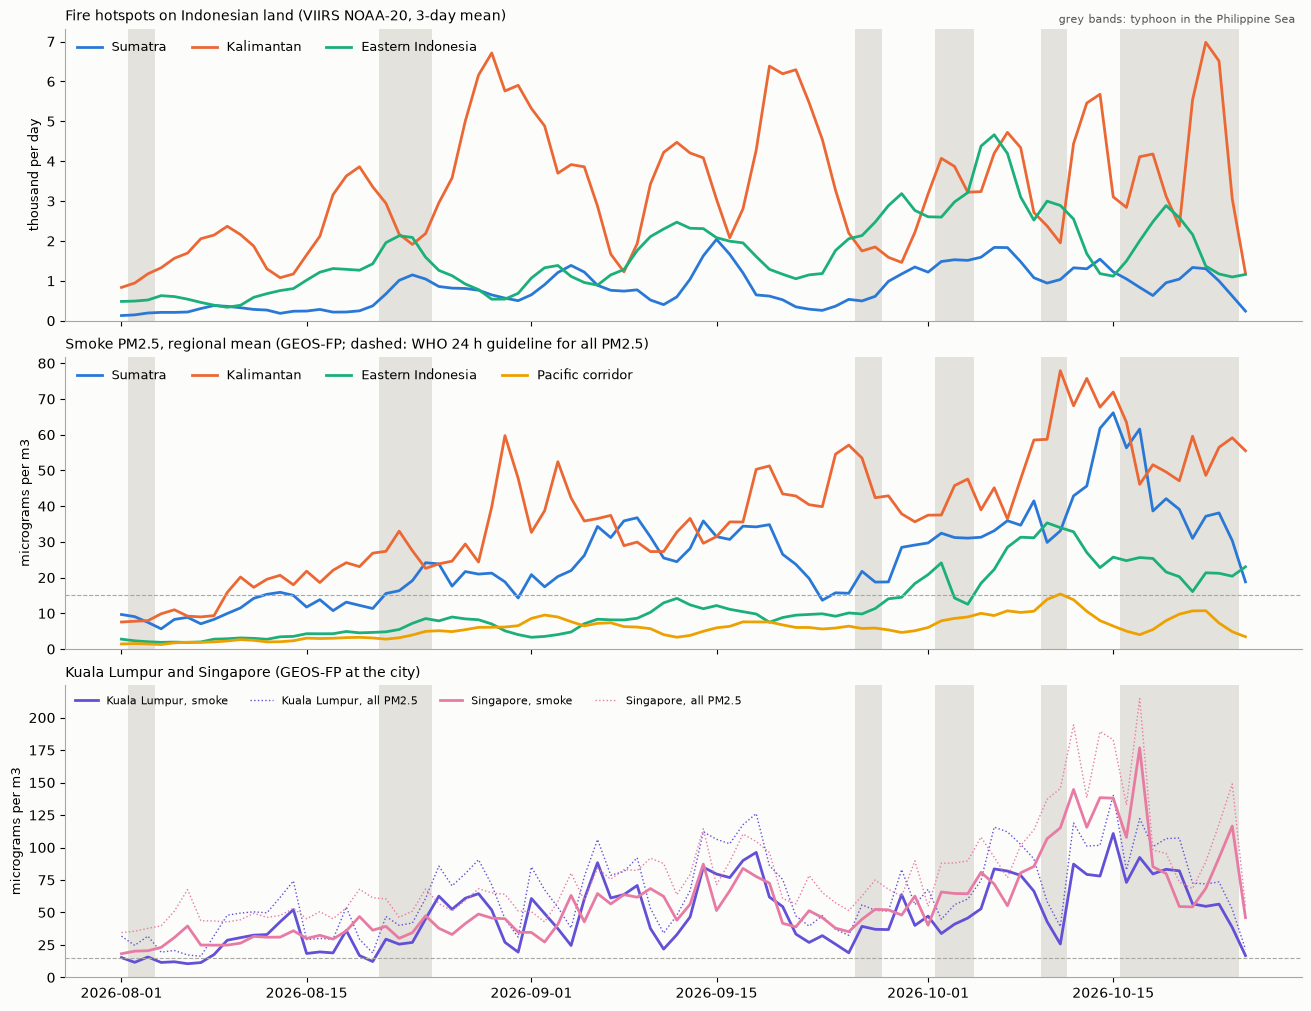

Monthly mean smoke PM2.5 (micrograms per m3):
place      Sumatra  Kalimantan  Eastern Indonesia  Pacific corridor  Kuala Lumpur  Singapore
August        14.0        21.9                4.5               3.2          29.4       33.3
September     26.3        39.4                9.8               6.3          51.8       54.5
October       38.9        54.1               24.0               8.8          63.5       90.0


In [5]:
def shade_tc(ax):
    on = TC.values.astype(int)
    starts = np.flatnonzero(np.diff(np.r_[0, on]) == 1)
    ends = np.flatnonzero(np.diff(np.r_[on, 0]) == -1)
    for a, b in zip(starts, ends):
        ax.axvspan(DAYS[a] - pd.Timedelta(hours=12), DAYS[b] + pd.Timedelta(hours=12), color=TC_SHADE, zorder=0, lw=0)


fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True, constrained_layout=True)
ax = axes[0]
for name in fire_daily:
    ax.plot(DAYS, fire_daily[name].rolling(3, center=True, min_periods=1).mean() / 1000, color=REGION_COLORS[name], lw=2, label=name)
ax.set_ylabel("thousand per day", fontsize=9)
ax.set_title("Fire hotspots on Indonesian land (VIIRS NOAA-20, 3-day mean)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, ncol=3)
ax = axes[1]
for name in REGIONS:
    ax.plot(DAYS, daily[(name, "smoke")], color=REGION_COLORS[name], lw=2, label=name)
ax.axhline(WHO_24H, color="#a8a7a2", lw=0.8, ls="--")
ax.set_ylabel("micrograms per m3", fontsize=9)
ax.set_title("Smoke PM2.5, regional mean (GEOS-FP; dashed: WHO 24 h guideline for all PM2.5)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=9, ncol=4)
ax = axes[2]
for city in CITIES:
    ax.plot(DAYS, daily[(city, "smoke")], color=CITY_COLORS[city], lw=2, label=f"{city}, smoke")
    ax.plot(DAYS, daily[(city, "pm25")], color=CITY_COLORS[city], lw=1, ls=":", label=f"{city}, all PM2.5")
ax.axhline(WHO_24H, color="#a8a7a2", lw=0.8, ls="--")
ax.set_ylabel("micrograms per m3", fontsize=9)
ax.set_title("Kuala Lumpur and Singapore (GEOS-FP at the city)", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, ncol=4)
for a in axes:
    shade_tc(a)
    a.set_ylim(bottom=0)
    a.spines[["top", "right"]].set_visible(False)
axes[0].text(0.995, 1.02, "grey bands: typhoon in the Philippine Sea", transform=axes[0].transAxes, ha="right", fontsize=8, color="#52514e")
fig.savefig(FIG_DIR / "season_overview.png", dpi=110)
plt.show()

monthly = daily.xs("smoke", axis=1, level="variable").resample("MS").mean().round(1)
monthly.index = monthly.index.strftime("%B")
print("Monthly mean smoke PM2.5 (micrograms per m3):")
print(monthly.to_string())

## Section 3: typhoon days compared with other days

For each place and variable: mean anomaly on typhoon days minus mean anomaly on other days, with a 95% interval from the block bootstrap. An interval that does not cross zero suggests a real difference in this season.

Variables: smoke PM2.5, fire hotspots (does the fire activity itself change?), rain (mm/day), boundary layer height (m; lower = smoke trapped near the ground), 10 m wind speed and the northward wind component (positive = wind blowing towards the north).

In [6]:
def anomaly(s):
    return s - s.rolling(ANOMALY_WINDOW_DAYS, center=True, min_periods=ANOMALY_WINDOW_DAYS // 2).mean()


def block_boot_diff(x, flag):
    n = len(x)
    n_blocks = int(np.ceil(n / BOOT_BLOCK_DAYS))
    starts_all = np.arange(n - BOOT_BLOCK_DAYS + 1)
    out = np.empty(BOOT_REPS)
    for r in range(BOOT_REPS):
        starts = rng.choice(starts_all, size=n_blocks)
        idx = (starts[:, None] + np.arange(BOOT_BLOCK_DAYS)[None, :]).ravel()[:n]
        xs = x[idx]
        fs = flag[idx]
        out[r] = xs[fs].mean() - xs[~fs].mean() if fs.any() and (~fs).any() else np.nan
    return np.nanpercentile(out, [2.5, 97.5])


def compare(flag_series, label):
    rows = []
    flag = flag_series.values
    for (place, var) in daily.columns:
        if place == "All" or var == "v10" and place in CITIES:
            continue
        a = anomaly(daily[(place, var)])
        ok = a.notna().values
        x = a.values[ok]
        f = flag[ok]
        diff = x[f].mean() - x[~f].mean()
        lo, hi = block_boot_diff(x, f)
        base = daily[(place, var)].mean()
        rows.append({"definition": label, "place": place, "variable": var, "typhoon_days": int(f.sum()), "other_days": int((~f).sum()), "difference": diff, "ci_low": lo, "ci_high": hi, "season_mean": base, "difference_pct": 100 * diff / base if base else np.nan})
    return pd.DataFrame(rows)


res = compare(TC, f"at least {TC_MIN_KT} kt, Philippine Sea")
res_loose = compare(TC_LOOSE, f"at least {TC_MIN_KT_LOOSE} kt, larger box")
both = pd.concat([res, res_loose], ignore_index=True)
both.round(3).to_csv(SEASON_DIR / "typhoon_day_effects.csv", index=False)
show = res[["place", "variable", "difference", "ci_low", "ci_high", "difference_pct"]].copy()
show["clear"] = np.where((show["ci_low"] > 0) | (show["ci_high"] < 0), "yes", "")
print(f"Typhoon days minus other days (anomalies), main definition, {int(TC.sum())} typhoon days:")
print(show.round(2).to_string(index=False))
print()
chk = res_loose[res_loose["variable"] == "smoke"][["place", "difference", "ci_low", "ci_high"]]
print(f"Check with the loose definition ({int(TC_LOOSE.sum())} days), smoke only:")
print(chk.round(2).to_string(index=False))

Typhoon days minus other days (anomalies), main definition, 22 typhoon days:
            place variable  difference   ci_low  ci_high  difference_pct clear
          Sumatra    smoke       -1.16    -5.17     2.65           -4.54      
          Sumatra     rain        1.23    -0.63     2.78           23.86      
          Sumatra      blh        3.95   -29.39    34.39            0.69      
          Sumatra     wspd        0.00    -0.39     0.38            0.05      
          Sumatra      v10        0.15    -0.24     0.57            7.08      
          Sumatra hotspots       51.56  -217.67   285.30            6.37      
       Kalimantan    smoke       -0.56    -4.63     4.18           -1.51      
       Kalimantan     rain        0.35    -0.46     1.47           24.30      
       Kalimantan      blh      -11.79   -44.50    12.89           -2.00      
       Kalimantan     wspd       -0.02    -0.21     0.15           -0.77      
       Kalimantan      v10        0.01    -0.18     0.

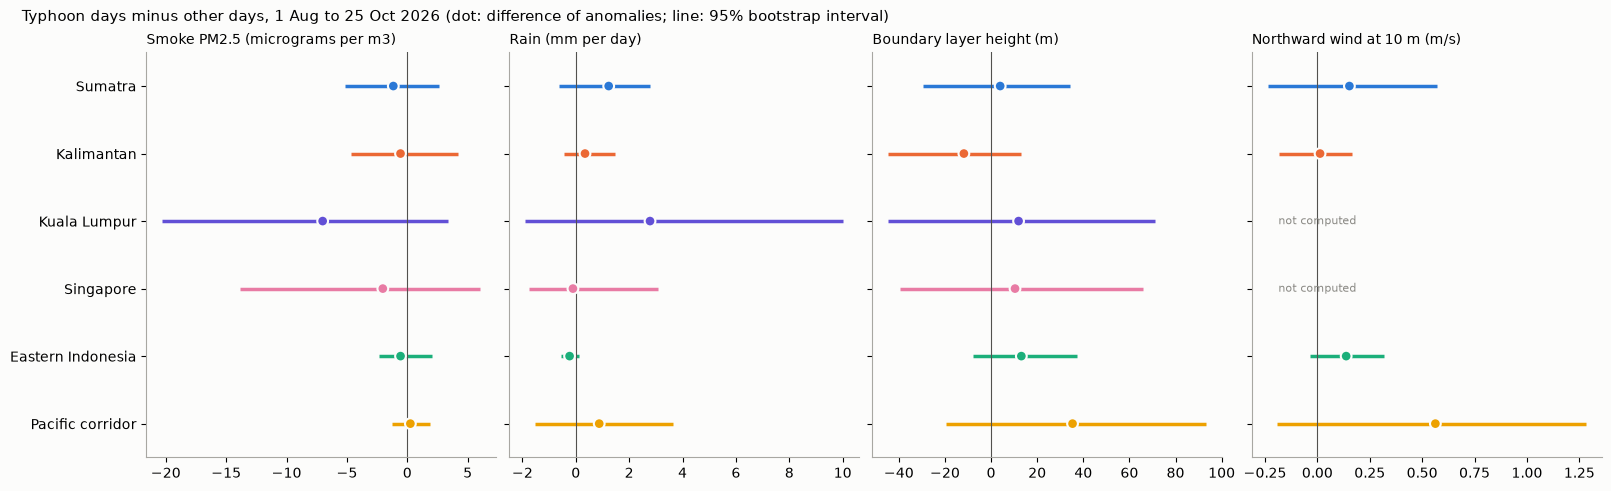

In [7]:
order_places = ["Sumatra", "Kalimantan", "Kuala Lumpur", "Singapore", "Eastern Indonesia", "Pacific corridor"]
panels = [("smoke", "Smoke PM2.5 (micrograms per m3)"), ("rain", "Rain (mm per day)"), ("blh", "Boundary layer height (m)"), ("v10", "Northward wind at 10 m (m/s)")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.8), sharey=True, constrained_layout=True)
for ax, (var, title) in zip(axes, panels):
    sub = res[res["variable"] == var].set_index("place").reindex(order_places)
    y = np.arange(len(order_places))
    colors = [REGION_COLORS.get(p, CITY_COLORS.get(p)) for p in order_places]
    ax.hlines(y, sub["ci_low"], sub["ci_high"], color=colors, lw=2.5)
    ax.scatter(sub["difference"], y, color=colors, s=60, zorder=5, edgecolor="#fcfcfb", linewidth=1.5)
    for k, p in enumerate(order_places):
        if np.isnan(sub["difference"].iloc[k]):
            ax.text(0, k, "not computed", ha="center", va="center", fontsize=8, color="#8a8984")
    ax.axvline(0, color="#52514e", lw=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(order_places)
    ax.set_ylim(len(order_places) - 0.5, -0.5)
    ax.set_title(title, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"Typhoon days minus other days, 1 Aug to {DAYS[-1]:%d %b} 2026 (dot: difference of anomalies; line: 95% bootstrap interval)", x=0.01, ha="left", fontsize=11)
fig.savefig(FIG_DIR / "typhoon_day_effects.png", dpi=110)
plt.show()

## Section 4: what a typhoon day looks like across the region

Mean anomaly on typhoon days minus mean anomaly on other days, at every grid point: smoke PM2.5, rain, and the 10 m wind (arrows show how the wind on typhoon days differs from other days). Orange means more smoke (or rain) than usual on typhoon days, blue means less.

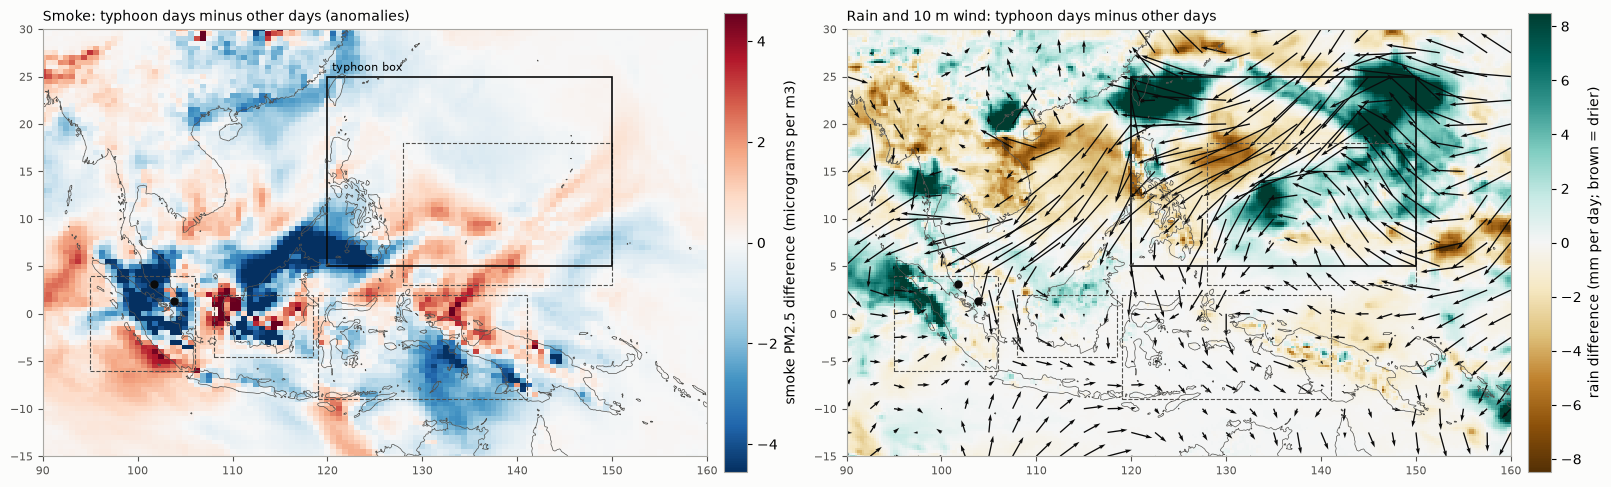

In [8]:
def anom_field(da):
    return da - da.rolling(time=ANOMALY_WINDOW_DAYS, center=True, min_periods=ANOMALY_WINDOW_DAYS // 2).mean()


tc_da = xr.DataArray(TC.values, coords={"time": geos.time.values}, dims="time")
d_smoke = anom_field(geos["smoke"]).where(tc_da).mean("time") - anom_field(geos["smoke"]).where(~tc_da).mean("time")
tc_e = xr.DataArray(TC.values, coords={"time": era5.time.values}, dims="time")
d_rain = anom_field(era5["tp"]).where(tc_e).mean("time") - anom_field(era5["tp"]).where(~tc_e).mean("time")
d_u = era5["u10"].where(tc_e).mean("time") - era5["u10"].where(~tc_e).mean("time")
d_v = era5["v10"].where(tc_e).mean("time") - era5["v10"].where(~tc_e).mean("time")

coast = []
for feat in json.loads((COAST_DIR / "ne_50m_coastline.geojson").read_text(encoding="utf8"))["features"]:
    g = feat["geometry"]
    coast += [np.array(p) for p in (g["coordinates"] if g["type"] == "MultiLineString" else [g["coordinates"]])]


def draw_base(ax, extent=MAP_EXTENT):
    for line in coast:
        ax.plot(line[:, 0], line[:, 1], color="#52514e", lw=0.5)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.set_aspect("equal")
    ax.tick_params(labelsize=8, colors="#52514e")


fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), constrained_layout=True)
lim_s = float(np.nanpercentile(np.abs(d_smoke), 98))
m = axes[0].pcolormesh(d_smoke.lon, d_smoke.lat, d_smoke, cmap="RdBu_r", vmin=-lim_s, vmax=lim_s, shading="auto")
fig.colorbar(m, ax=axes[0], shrink=0.75, pad=0.01).set_label("smoke PM2.5 difference (micrograms per m3)")
axes[0].set_title("Smoke: typhoon days minus other days (anomalies)", loc="left", fontsize=10)
lim_r = float(np.nanpercentile(np.abs(d_rain), 98))
m = axes[1].pcolormesh(d_rain.lon, d_rain.lat, d_rain, cmap="BrBG", vmin=-lim_r, vmax=lim_r, shading="auto")
fig.colorbar(m, ax=axes[1], shrink=0.75, pad=0.01).set_label("rain difference (mm per day; brown = drier)")
axes[1].set_title("Rain and 10 m wind: typhoon days minus other days", loc="left", fontsize=10)
s = 10
axes[1].quiver(d_u.lon[::s], d_u.lat[::s], d_u[::s, ::s], d_v[::s, ::s], color="#0b0b0b", scale=40, width=0.002)
for ax in axes:
    draw_base(ax)
    for name, b in REGIONS.items():
        ax.add_patch(plt.Rectangle((b[0], b[2]), b[1] - b[0], b[3] - b[2], fill=False, lw=0.8, ls="--", ec="#52514e"))
    ax.add_patch(plt.Rectangle((TC_BOX[0], TC_BOX[2]), TC_BOX[1] - TC_BOX[0], TC_BOX[3] - TC_BOX[2], fill=False, lw=1.2, ec="#0b0b0b"))
    for city, (clat, clon) in CITIES.items():
        ax.scatter([clon], [clat], s=25, color="#0b0b0b", zorder=5)
axes[0].text(TC_BOX[0] + 0.5, TC_BOX[3] + 0.6, "typhoon box", fontsize=8)
fig.savefig(FIG_DIR / "typhoon_day_maps.png", dpi=110)
plt.show()

## Section 5: season animation

One frame per day: smoke PM2.5, fire cells of that day (NOAA-20, dot size = number of hotspots) and every storm active that day (track so far, current position, name and wind). Frames go to `data/processed/season/frames/`, the GIF to `data/processed/season/season_smoke.gif`. Takes about 1 to 2 minutes.

In [9]:
norm = BoundaryNorm(SMOKE_LEVELS, plt.get_cmap("Oranges").N, extend="max")
fires_by_day = {d: g for d, g in pd.read_csv(RAW_SEASON / FIRMS_FILE, parse_dates=["date"]).groupby("date")}
frame_files = []
for i, day in enumerate(DAYS):
    fig, ax = plt.subplots(figsize=(11, 7.6), constrained_layout=True)
    f = geos["smoke"].isel(time=i)
    mesh = ax.pcolormesh(f.lon, f.lat, f, cmap="Oranges", norm=norm, shading="auto")
    ax.contour(f.lon, f.lat, f, levels=[5, WHO_24H], colors=["#52514e", "#0b0b0b"], linewidths=[0.5, 0.9])
    draw_base(ax)
    fd = fires_by_day.get(day)
    if fd is not None:
        ax.scatter(fd["cell_lon"], fd["cell_lat"], s=np.clip(fd["hotspots"], 1, 200) * 0.15, color="#2a78d6", alpha=0.6, lw=0)
    active = tracks[(tracks["day"] <= day)].groupby("SID")
    for sid, g in active:
        if g["day"].max() < day:
            continue
        ax.plot(g["LON"], g["LAT"], color="#0b0b0b", lw=1.2)
        now = g[g["day"] == day].iloc[-1]
        ax.scatter([now["LON"]], [now["LAT"]], s=60, facecolor="none", edgecolor="#0b0b0b", lw=1.8, zorder=5)
        ax.text(now["LON"] + 0.8, now["LAT"] + 0.5, f"{now['NAME'].title()} {now['wind']:.0f} kt", fontsize=8, color="#0b0b0b")
    tag = "   typhoon in the Philippine Sea" if TC.iloc[i] else ""
    ax.set_title(f"{day:%d %b %Y}   smoke PM2.5 (GEOS-FP daily mean){tag}", loc="left", fontsize=11)
    fig.colorbar(mesh, ax=ax, shrink=0.75, pad=0.01, ticks=SMOKE_LEVELS, format="%g").set_label("micrograms per m3", fontsize=9)
    path = FRAME_DIR / f"day_{i:03d}.png"
    fig.savefig(path, dpi=90)
    plt.close(fig)
    frame_files.append(path)
images = [Image.open(p).convert("P", palette=Image.ADAPTIVE, colors=128) for p in frame_files]
gif_path = SEASON_DIR / "season_smoke.gif"
images[0].save(gif_path, save_all=True, append_images=images[1:], duration=int(1000 / GIF_FPS), loop=0)
print(f"{len(frame_files)} frames, GIF {gif_path.stat().st_size / 1e6:.1f} MB")

86 frames, GIF 6.5 MB


___
**END**